<a href="https://colab.research.google.com/github/nilaynishant/acrs/blob/main/11_parking_spot_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parking Spot Detection


This notebook detects parking spots in an aerial image with `geoai` and visualizes every step with static `rioxarray` + `matplotlib` plots.

## Install packages
Ensure `geoai-py` and `rioxarray` are installed in your environment. Uncomment the command below if needed.

In [1]:
%pip install -q geoai-py rioxarray

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.0/117.0 kB 4.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 651.5/651.5 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 669.2/669.2 kB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.3/46.3 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 44.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 60.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 812.4/812.4 kB 40.6 MB/s eta 0:00:00
   ━━━━━

## Import libraries

In [5]:
import geoai
import geopandas as gpd
import matplotlib.pyplot as plt
import rioxarray as rxr

## Download sample data

We will download a sample image from Hugging Face Hub to use for parking spot detection. You can find more high-resolution images from [OpenAerialMap](https://openaerialmap.org).

In [3]:
raster_url = (
    "https://huggingface.co/datasets/giswqs/geospatial/resolve/main/parking_spots.tif"
)

In [7]:
raster_path = geoai.download_file(raster_url)

## Visualize the image

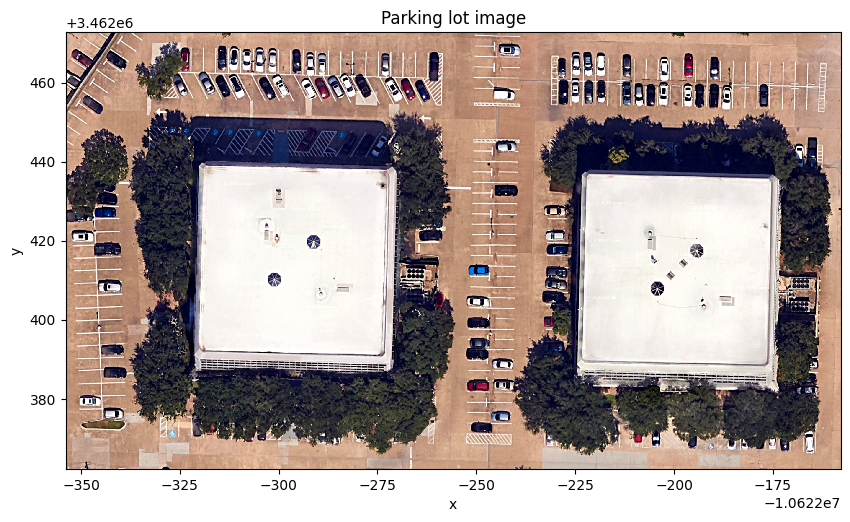

In [8]:
da = rxr.open_rasterio(raster_path, masked=True)  # dims: band, y, x
rgb = da.sel(band=[1, 2, 3])


def show_rgb(ax, title=None):
    """Draw the RGB image (2-98% stretch) on a matplotlib axis."""
    rgb.plot.imshow(ax=ax, robust=True)
    ax.set_title(title)
    ax.set_aspect("equal")
    return ax


fig, ax = plt.subplots(figsize=(10, 10))
show_rgb(ax, "Parking lot image")
plt.show()

## Initialize the model

In [9]:
detector = geoai.ParkingSpotDetector()

parking_spot_detection.safetensors: reconstructing file:   0%|          |  0.00B /  176MB            

parking_spot_detection.safetensors: downloading bytes:           |  0.00B            

## Extract parking spots

Extract parking spots from the image using the model and save the output image.

In [ ]:
mask_path = detector.generate_masks(
    raster_path=raster_path,
    output_path="parking_masks.tif",
    confidence_threshold=0.5,
    mask_threshold=0.5,
    overlap=0.25,
    chip_size=(256, 256),
    min_object_area=10,
    # max_object_area=5000,
)

Convert the image masks to polygons and save the output GeoJSON file.

In [ ]:
gdf = detector.vectorize_masks(
    masks_path="parking_masks.tif",
    output_path="parking.geojson",
    min_object_area=300,
    # max_object_area=5000,
)

## Add geometric properties

In [ ]:
gdf = geoai.add_geometric_properties(gdf)

## Visualize results

In [ ]:
gdf_plot = gdf.to_crs(da.rio.crs)

fig, ax = plt.subplots(figsize=(10, 10))
show_rgb(ax, "Detected parking spots")
gdf_plot.plot(
    ax=ax,
    column="confidence",
    cmap="viridis",
    alpha=0.6,
    edgecolor="red",
    linewidth=0.5,
    legend=True,
    legend_kwds={"label": "Confidence", "shrink": 0.7},
)
plt.show()